# Lab 11: Solving XOR with a Multi-Layer Network

MLPR, Semester 4. A 2-8-1 network (ReLU hidden layer, sigmoid output) trained with SGD on the XOR problem. It compares four training schemes: a constant learning rate, momentum, an adaptive learning rate, and adaptive with momentum. Training stops when the loss falls below 0.001.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)


def train_model(initial_lr=0.1, use_momentum=False, use_adaptive=False, target_loss=0.001, max_epochs=20000, seed=1):
    tf.keras.utils.set_random_seed(seed)
    lr = initial_lr
    model = Sequential([Input(shape=(2,)), Dense(8, activation="relu"), Dense(1, activation="sigmoid")])
    model.compile(optimizer=SGD(learning_rate=lr, momentum=0.9 if use_momentum else 0.0), loss="mean_squared_error")

    losses, learning_rates, epoch, prev_loss = [], [], 0, np.inf
    while epoch < max_epochs:
        curr_loss = model.fit(X, y, epochs=5, verbose=0).history["loss"][-1]
        epoch += 5
        losses.append(curr_loss)
        if use_adaptive:
            # Heuristics: cut the rate if the loss rose by more than 4%, raise it if the loss fell
            if curr_loss > prev_loss * 1.04:
                lr *= 0.7
            elif curr_loss < prev_loss:
                lr *= 1.05
            model.optimizer.learning_rate.assign(lr)
        learning_rates.append(lr)
        prev_loss = curr_loss
        if curr_loss < target_loss:
            break
    return epoch, losses, learning_rates, model

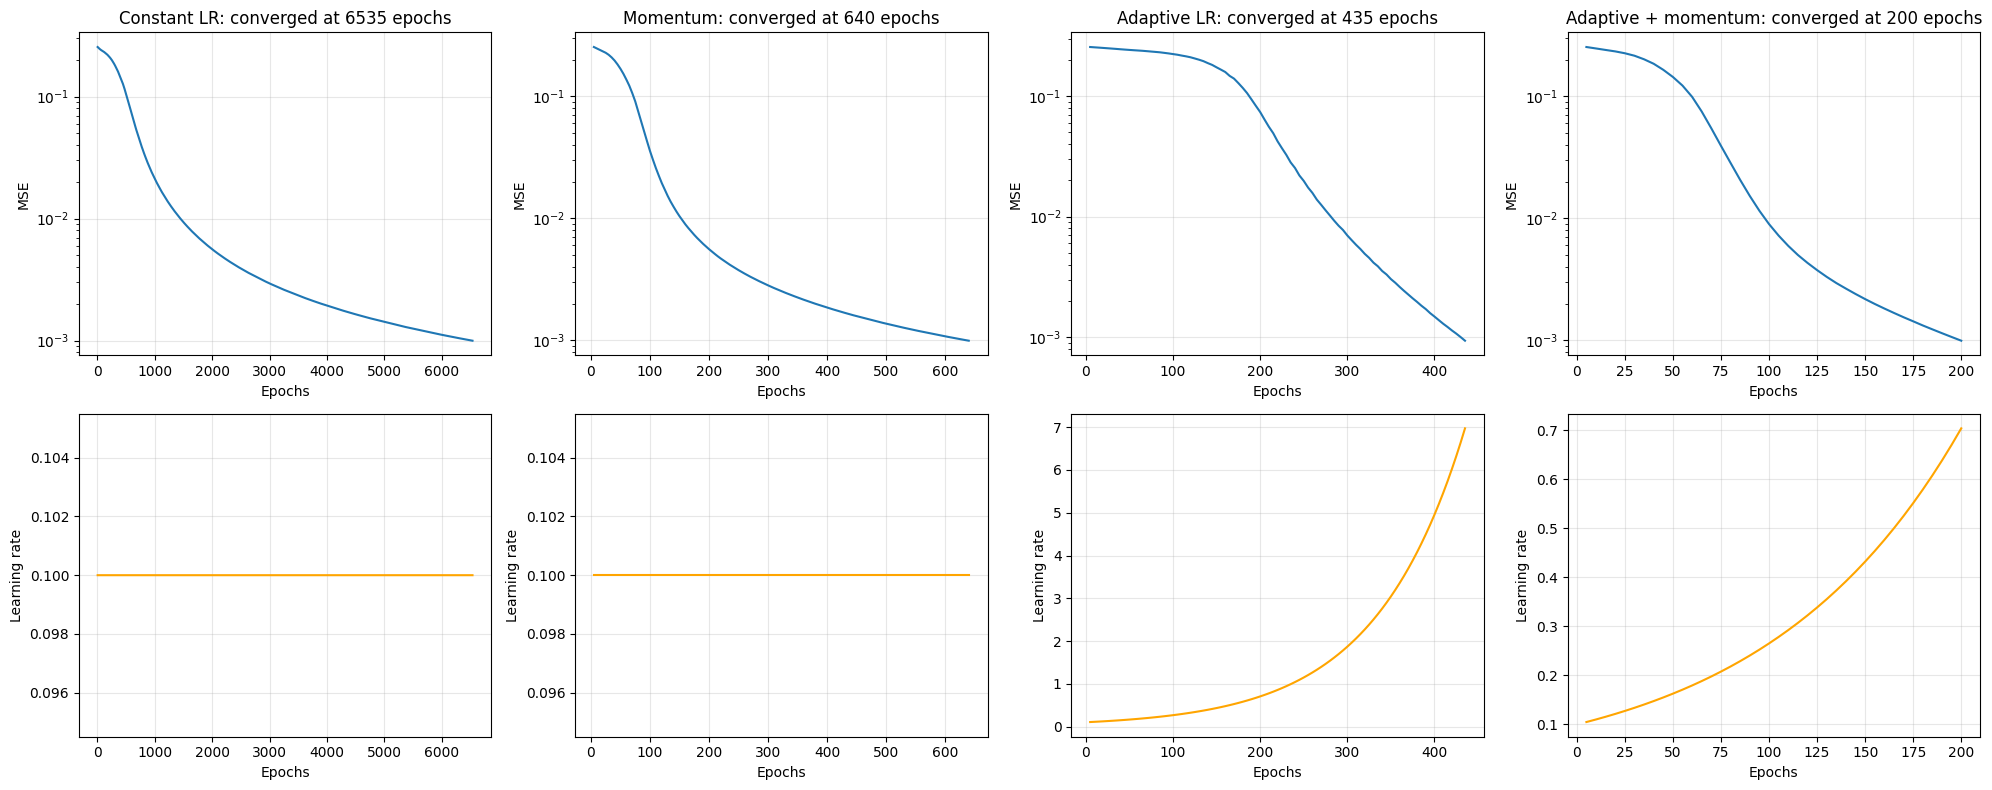

Constant LR            epochs = 6535   final MSE = 0.00100   outputs for 00, 01, 10, 11 = [0.054 0.979 0.979 0.015]
Momentum               epochs = 640    final MSE = 0.00099   outputs for 00, 01, 10, 11 = [0.053 0.979 0.978 0.015]
Adaptive LR            epochs = 435    final MSE = 0.00094   outputs for 00, 01, 10, 11 = [0.052 0.98  0.979 0.015]
Adaptive + momentum    epochs = 200    final MSE = 0.00099   outputs for 00, 01, 10, 11 = [0.053 0.98  0.978 0.015]


In [2]:
cases = [("Constant LR", False, False), ("Momentum", True, False),
         ("Adaptive LR", False, True), ("Adaptive + momentum", True, True)]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
summary = []
for col, (title, mom, adapt) in enumerate(cases):
    epochs, losses, lrs, model = train_model(0.1, mom, adapt)
    preds = model.predict(X, verbose=0).ravel()
    summary.append((title, epochs, losses[-1], np.round(preds, 3)))
    x_axis = np.arange(5, epochs + 1, 5)
    axes[0, col].semilogy(x_axis, losses)
    axes[0, col].set_title(f"{title}: converged at {epochs} epochs")
    axes[0, col].set_xlabel("Epochs"); axes[0, col].set_ylabel("MSE")
    axes[1, col].plot(x_axis, lrs, color="orange")
    axes[1, col].set_xlabel("Epochs"); axes[1, col].set_ylabel("Learning rate")
    for ax in axes[:, col]: ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/lab11_xor.png")
plt.show()

for title, epochs, loss, preds in summary:
    print(f"{title:<22} epochs = {epochs:<6} final MSE = {loss:.5f}   outputs for 00, 01, 10, 11 = {preds}")

Momentum and the adaptive learning rate both reach the target loss in far fewer epochs than plain SGD with a constant learning rate. After training, the outputs for (0,0), (0,1), (1,0) and (1,1) are close to 0, 1, 1 and 0, so the network has learned XOR.

## Report

**Q1. How does a multilayer network solve XOR?** XOR is not linearly separable, so a single perceptron fails. A hidden layer with a non-linear activation (ReLU here) transforms the inputs into a representation where the classes become separable. This gives a non-linear decision boundary.

**Q2. Why are the middle layers called "hidden"?** Their inputs and outputs are not seen directly: they are neither the network's input nor its output. They only hold intermediate representations used inside the model.

**Q3. Hyperparameters vs parameters:** parameters (weights and biases) are learned from the data. Hyperparameters (learning rate, momentum, number of layers and neurons, epochs) are chosen before training and control how learning happens.

**Q4. Accelerated learning:** momentum accumulates past gradients to move faster along consistent directions and damp oscillations. An adaptive learning rate grows the step while the loss keeps falling and shrinks it when the loss rises. Both speed up convergence.

**Q5. The two adaptive heuristics used:** if the loss increases by more than 4% compared with the previous check, multiply the learning rate by 0.7; if the loss decreases, multiply it by 1.05.